In [53]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import os
print("libraries imported successfully.")

libraries imported successfully.


In [54]:
DATA_DIR= Path("../data/raw/epl_matches_2010_2021")
csv_files=sorted(DATA_DIR.glob("*.csv"))
print("Total CSV files: ", len(csv_files))
for file in csv_files:
    print(file.name)

Total CSV files:  11
epl_2010_11.csv
epl_2011_12.csv
epl_2012_13.csv
epl_2013_14.csv
epl_2014_15.csv
epl_2015_16.csv
epl_2016_17.csv
epl_2017_18.csv
epl_2018_19.csv
epl_2019_20.csv
epl_2020_21.csv


In [55]:
#Checking one csv file
df=pd.read_csv(csv_files[0])
print(df.shape)
print(df.head())
print(df.columns.tolist())
print(df.dtypes)
print(df.isna().sum())
print(df.columns.str.strip())


(380, 5)
   Round             Date                      Team 1   FT              Team 2
0      1  Sat Aug 14 2010         Bolton Wanderers FC  0-0           Fulham FC
1      1  Sat Aug 14 2010           Wigan Athletic FC  0-4        Blackpool FC
2      1  Sat Aug 14 2010              Aston Villa FC  3-0  West Ham United FC
3      1  Sat Aug 14 2010  Wolverhampton Wanderers FC  2-1       Stoke City FC
4      1  Sat Aug 14 2010              Sunderland AFC  2-2  Birmingham City FC
['Round', 'Date', 'Team 1', 'FT', 'Team 2']
Round     int64
Date        str
Team 1      str
FT          str
Team 2      str
dtype: object
Round     0
Date      0
Team 1    0
FT        0
Team 2    0
dtype: int64
Index(['Round', 'Date', 'Team 1', 'FT', 'Team 2'], dtype='str')


In [56]:
#Loading all
dataframes=[]
for file in csv_files:
    df=pd.read_csv(file)
    #Track the source CSV file for each record
    df["Source_File"]=file.stem
    dataframes.append(df)

#Combining all seasons:
raw_matches=pd.concat(dataframes, ignore_index=True)
print("Combined Dataset Shape: ", raw_matches.shape)
print(raw_matches.head())
print(f"Total Matches: {len(raw_matches)}")
print(f"Coulmns: {raw_matches.columns.tolist()}")
print(f"Data Types: {raw_matches.dtypes}")


Combined Dataset Shape:  (4180, 6)
   Round             Date  ...              Team 2  Source_File
0      1  Sat Aug 14 2010  ...           Fulham FC  epl_2010_11
1      1  Sat Aug 14 2010  ...        Blackpool FC  epl_2010_11
2      1  Sat Aug 14 2010  ...  West Ham United FC  epl_2010_11
3      1  Sat Aug 14 2010  ...       Stoke City FC  epl_2010_11
4      1  Sat Aug 14 2010  ...  Birmingham City FC  epl_2010_11

[5 rows x 6 columns]
Total Matches: 4180
Coulmns: ['Round', 'Date', 'Team 1', 'FT', 'Team 2', 'Source_File']
Data Types: Round          int64
Date             str
Team 1           str
FT               str
Team 2           str
Source_File      str
dtype: object


In [57]:
#Renaming the column names:
matches=raw_matches.rename(columns={
    "Round": "MatchWeek",
    "Date": "Date",
    "Team 1": "HomeTeam",
    "FT": "FullTimeScore",
    "Team 2": "AwayTeam"
}).copy()
print("Rows: ", matches.shape[0])
print("Columns: ", matches.shape[1])
print(matches.tail())
print(matches.sample(5, random_state=42))
print(matches.info())
matches.head(10)

Rows:  4180
Columns:  6
      MatchWeek             Date  ...        AwayTeam  Source_File
4175         38  Sun May 23 2021  ...     Southampton  epl_2020_21
4176         38  Sun May 23 2021  ...       West Brom  epl_2020_21
4177         38  Sun May 23 2021  ...        Brighton  epl_2020_21
4178         38  Sun May 23 2021  ...  Crystal Palace  epl_2020_21
4179         38  Sun May 23 2021  ...   Newcastle Utd  epl_2020_21

[5 rows x 6 columns]
      MatchWeek             Date  ...                 AwayTeam  Source_File
1263         13  Sat Nov 30 2013  ...  West Bromwich Albion FC  epl_2013_14
1163          3  Sat Aug 31 2013  ...            Stoke City FC  epl_2013_14
3250         22  Sat Jan 12 2019  ...               Arsenal FC  epl_2018_19
810           6  Sat Sep 29 2012  ...           Southampton FC  epl_2012_13
3295         26   Sat Feb 9 2019  ...       West Ham United FC  epl_2018_19

[5 rows x 6 columns]
<class 'pandas.DataFrame'>
RangeIndex: 4180 entries, 0 to 4179
Data column

,MatchWeek,Date,HomeTeam,FullTimeScore,AwayTeam,Source_File
0,1,Sat Aug 14 2010,Bolton Wanderers FC,0-0,Fulham FC,epl_2010_11
1,1,Sat Aug 14 2010,Wigan Athletic FC,0-4,Blackpool FC,epl_2010_11
2,1,Sat Aug 14 2010,Aston Villa FC,3-0,West Ham United FC,epl_2010_11
3,1,Sat Aug 14 2010,Wolverhampton Wanderers FC,2-1,Stoke City FC,epl_2010_11
4,1,Sat Aug 14 2010,Sunderland AFC,2-2,Birmingham City FC,epl_2010_11
5,1,Sat Aug 14 2010,Blackburn Rovers FC,1-0,Everton FC,epl_2010_11
6,1,Sat Aug 14 2010,Tottenham Hotspur FC,0-0,Manchester City FC,epl_2010_11
7,1,Sat Aug 14 2010,Chelsea FC,6-0,West Bromwich Albion FC,epl_2010_11
8,1,Sun Aug 15 2010,Liverpool FC,1-1,Arsenal FC,epl_2010_11
9,1,Mon Aug 16 2010,Manchester United FC,3-0,Newcastle United FC,epl_2010_11


In [58]:
# Checking values and duplicates
missing_values=matches.isnull().sum()
print(missing_values)
missing_percentage=(matches.isnull().mean()*100).round(2)
print(missing_percentage)
print(matches.duplicated().sum())
duplicates=matches[matches.duplicated(keep=False)]
print(duplicates.head(20))

MatchWeek        0
Date             0
HomeTeam         0
FullTimeScore    0
AwayTeam         0
Source_File      0
dtype: int64
MatchWeek        0.0
Date             0.0
HomeTeam         0.0
FullTimeScore    0.0
AwayTeam         0.0
Source_File      0.0
dtype: float64
0
Empty DataFrame
Columns: [MatchWeek, Date, HomeTeam, FullTimeScore, AwayTeam, Source_File]
Index: []


In [59]:
# Check date info
matches["Date"]=pd.to_datetime(
    matches["Date"], 
    errors="coerce",
    dayfirst=True
)
print(matches["Date"].dtype)
print("First Match: ",{matches["Date"].min()})
print("Last Match: ",{matches["Date"].max()})
print("Invalid dates: ", matches["Date"].isna().sum())
invalid_dates = matches[matches["Date"].isna()]
display(invalid_dates[["Date", "HomeTeam", "AwayTeam","FullTimeScore", "Source_File"]])

datetime64[us]
First Match:  {Timestamp('2010-08-14 00:00:00')}
Last Match:  {Timestamp('2021-05-23 00:00:00')}
Invalid dates:  12


,Date,HomeTeam,AwayTeam,FullTimeScore,Source_File
3808,NaT,Burnley,Manchester Utd,0–1,epl_2020_21
3809,NaT,Manchester City,Aston Villa,2–0,epl_2020_21
3909,NaT,Aston Villa,Newcastle Utd,2–0,epl_2020_21
3958,NaT,Tottenham,Fulham,1–1,epl_2020_21
3959,NaT,Everton,Manchester City,1–3,epl_2020_21
3969,NaT,Burnley,Fulham,1–1,epl_2020_21
3978,NaT,Leeds United,Southampton,3–0,epl_2020_21
3979,NaT,Aston Villa,Tottenham,0–2,epl_2020_21
3989,NaT,Aston Villa,Everton,0–0,epl_2020_21
4089,NaT,Tottenham,Southampton,2–1,epl_2020_21


In [60]:
#Score processing
score_parts=matches["FullTimeScore"].astype("string").str.extract(r"^\s*(\d+)\s*[-–—:]\s*(\d+)\s*$")
matches["HomeGoals"]=pd.to_numeric(
    score_parts[0],
    errors="coerce"
)
matches["AwayGoals"]=pd.to_numeric(
    score_parts[1],
    errors="coerce"
)
print(matches[["HomeTeam", "FullTimeScore", "AwayTeam", "HomeGoals", "AwayGoals"]].head(10))
print("Invalid scores:",matches[["HomeGoals", "AwayGoals"]].isna().any(axis=1).sum())

                     HomeTeam FullTimeScore  ...  HomeGoals  AwayGoals
0         Bolton Wanderers FC           0-0  ...          0          0
1           Wigan Athletic FC           0-4  ...          0          4
2              Aston Villa FC           3-0  ...          3          0
3  Wolverhampton Wanderers FC           2-1  ...          2          1
4              Sunderland AFC           2-2  ...          2          2
5         Blackburn Rovers FC           1-0  ...          1          0
6        Tottenham Hotspur FC           0-0  ...          0          0
7                  Chelsea FC           6-0  ...          6          0
8                Liverpool FC           1-1  ...          1          1
9        Manchester United FC           3-0  ...          3          0

[10 rows x 5 columns]
Invalid scores: 0


In [61]:
#Predict whether home team win loss or draw.
conditions=[
    matches["HomeGoals"]>matches["AwayGoals"],
    matches["HomeGoals"]<matches["AwayGoals"],
    matches["HomeGoals"]==matches["AwayGoals"]
]
results=["HW", "AW", "D"]
matches["MatchResult"]=np.select(conditions, results, default=None)
print(matches[["HomeTeam", "HomeGoals","AwayGoals", "AwayTeam", "MatchResult"]].tail(10))
print(matches["MatchResult"].value_counts())
print("In percentage:", matches["MatchResult"].value_counts(normalize=True).mul(100).round(2))

             HomeTeam  HomeGoals  AwayGoals        AwayTeam MatchResult
4170      Aston Villa          2          1         Chelsea          HW
4171   Leicester City          2          4       Tottenham          AW
4172  Manchester City          5          0         Everton          HW
4173    Sheffield Utd          1          0         Burnley          HW
4174           Wolves          1          2  Manchester Utd          AW
4175         West Ham          3          0     Southampton          HW
4176     Leeds United          3          1       West Brom          HW
4177          Arsenal          2          0        Brighton          HW
4178        Liverpool          2          0  Crystal Palace          HW
4179           Fulham          0          2   Newcastle Utd          AW
MatchResult
HW    1881
AW    1280
D     1019
Name: count, dtype: int64
In percentage: MatchResult
HW    45.00
AW    30.62
D     24.38
Name: proportion, dtype: float64


Total Number of unique Teams: 

 56
Source_File
epl_2010_11    380
epl_2011_12    380
epl_2012_13    380
epl_2013_14    380
epl_2014_15    380
epl_2015_16    380
epl_2016_17    380
epl_2017_18    380
epl_2018_19    380
epl_2019_20    380
epl_2020_21    380
Name: count, dtype: int64


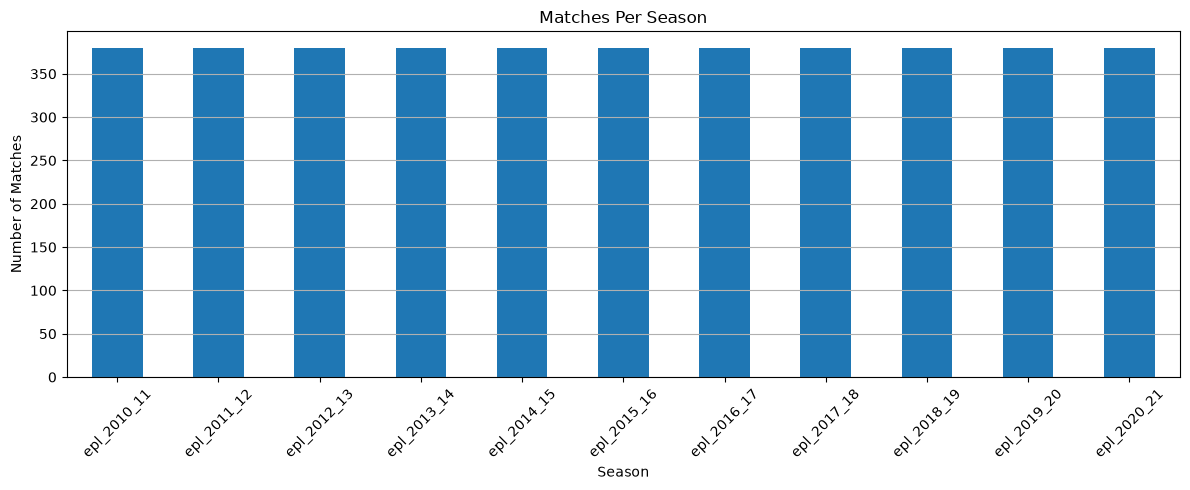

       HomeGoals  AwayGoals
count     4180.0     4180.0
mean    1.534211   1.206699
std      1.30217   1.177012
min          0.0        0.0
25%          1.0        0.0
50%          1.0        1.0
75%          2.0        2.0
max          9.0        9.0
Dataset saved successfully


In [62]:
#Exploring teams and seasons
# No of unique teams
all_teams=pd.concat([matches["HomeTeam"], matches["AwayTeam"]])
print("Total Number of unique Teams: ", all_teams.nunique())
#Match per season file
season_matches=matches["Source_File"].value_counts().sort_index()
print(season_matches)
#Visualize:
plt.figure(figsize=(12, 5))
season_matches.plot(kind="bar")
plt.title("Matches Per Season")
plt.xlabel("Season")
plt.ylabel("Number of Matches")
plt.xticks(rotation=45)
plt.grid(axis="y")
plt.tight_layout()
plt.show()
print(matches[["HomeGoals", "AwayGoals"]].describe())
os.makedirs("../data/processed", exist_ok=True)
matches.to_csv("../data/processed/epl_matches_stage1.csv")
print("Dataset saved successfully")

In [63]:
#REPORT
print("Total Matches: ", len(matches))
print("Unique Teams: ", all_teams.nunique())
print("Date Range: ", matches["Date"].min(), "to", matches["Date"].max())
print("Missing Values: ", matches.isnull().sum())
print("Duplicate Rows: ", matches.duplicated().sum())
print("Invalid Scores: ", matches[["HomeGoals", "AwayGoals"]].isna().any(axis=1).sum())
print("Match Result Distribution: ", matches["MatchResult"].value_counts())

Total Matches:  4180
Unique Teams:  56
Date Range:  2010-08-14 00:00:00 to 2021-05-23 00:00:00
Missing Values:  MatchWeek         0
Date             12
HomeTeam          0
FullTimeScore     0
AwayTeam          0
Source_File       0
HomeGoals         0
AwayGoals         0
MatchResult       0
dtype: int64
Duplicate Rows:  0
Invalid Scores:  0
Match Result Distribution:  MatchResult
HW    1881
AW    1280
D     1019
Name: count, dtype: int64
